 # NOTEBOOK CONTENT:
 ## David Mandado Loureiro (2025 Capstone)
### 1) Installations and Setup
> 1.1 Mount Google Drive <br>
> 1.2 Install Packages <br>
> 1.3 Define Global Paths

### 2) Dataset Integration
> 2.1 Load all datasets: <br>
>> - benthic dataset (Reef Support)<br>
>> - Bleaching dataset (Reef Support)<br>
>> - CoralScapes (Huggingface) <br>

> 2.2 Normalize all dataset to binary coral vs non-coral masks <br>
> 2.3 Build DataFrame (paths, site, split) <br>
> 2.4 Visualize class balance and site distribution <br>

### 3) Preprocessing
> 3.1 Remove empty masks/invalid pairs<br>
> 3.2 Remove very small coral regions<br>
> 3.3 Resize all images (512x512)<br>
> 3.4 Train/Val/Test split (site-stratified + balanced)<br>
> 3.5 Save manifest CSV

### 4) Model Setup and Training
> 4.1 Prepare DataLoader with augmentations (Albumentations)<br>
> 4.2 Define U-Net model (EfficientNet enconder)<br>
> 4.3 Loss (BCE + Dice), optimizer (AdamW), scheduler <br>
> 4.4 Training loop + progress logging <br>
> 4.5 Validation metrics (IoU, Dice)<br>
> 4.6 Result's visualizations <br>

### 5) Feature Extraction
> 5.1 Postprocess segmented coral masks <br>
> 5.2 Compute features: <br>
>> Texture: <br>
>>> - Lplacian Variance <br>
>>> - LBP Variance <br>
>>> - GLCM Contrast <br>

>> Paleness: <br>
>>> - Luminance <br>
>>> - Saturation <br>
>>> - HUE ... <br>

> 5.3 Visualize feature distributions and correlations <br>
> 5.4 Revisualize after applying grayscale (possibly something else) <br>
> 5.5 PCA and clustering exploration <br>

### 6) Feature Interpretation
> 6.1 Correlation plots, scatter matrices <br>
> 6.2 Site-level aggregation and variability <br>
> 6.3 Example of bleached/healthy and mid ranged samples per feature <br>


# Section 1: Installations and Setup

### 1.1 Mount Drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


### 1.2 Instal Packages
Install all required Python libraries for segmentation, image processing, and feature extraction.



In [ ]:
!pip install -q torch torchvision albumentations opencv-python-headless numpy pandas tqdm matplotlib scikit-image datasets segmentation-models-pytorch

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 13.0 MB/s eta 0:00:00


### 1.3 Define Global Paths
Define the locations of all datasets and prepare the output folder structure.


In [ ]:
import os
import cv2
import numpy as np
import pandas as pd
from tqdm import tqdm
import matplotlib.pyplot as plt
from datasets import load_dataset

# === BASE DIRECTORIES ===
BASE_DIR = "/content/drive/MyDrive/01_data"
OUTPUT_DIR = "/content/drive/MyDrive/coral_project_outputs"

# Dataset paths
PATH_BENTHIC = os.path.join(BASE_DIR, "benthic_datasets/mask_labels/reef_support")
PATH_CORALSEG = os.path.join(BASE_DIR, "benthic_datasets/mask_labels/Coralseg")
PATH_BLEACHING = os.path.join(BASE_DIR, "coral_bleaching/reef_support/UNAL_BLEACHING_TAYRONA")
PATH_CORALSCAPES = "ReefSupport/coralscapes"  # Hugging Face ID

In [ ]:
# === OUTPUT FOLDERS ===
os.makedirs(os.path.join(OUTPUT_DIR, "manifests"), exist_ok=True)
os.makedirs(os.path.join(OUTPUT_DIR, "processed_images"), exist_ok=True)
os.makedirs(os.path.join(OUTPUT_DIR, "models"), exist_ok=True)
os.makedirs(os.path.join(OUTPUT_DIR, "features"), exist_ok=True)
os.makedirs(os.path.join(OUTPUT_DIR, "figures"), exist_ok=True)

print("Folders ready.")
print("BASE_DIR:", BASE_DIR)
print("OUTPUT_DIR:", OUTPUT_DIR)

# === QUICK DATASET AVAILABILITY CHECK ===
datasets = {
    "Benthic (Reef Support)": PATH_BENTHIC,
    "CoralSeg": PATH_CORALSEG,
    "Bleaching (UNAL)": PATH_BLEACHING,
}

for name, path in datasets.items():
    exists = os.path.exists(path)
    print(f"{'yes' if exists else 'no'} {name}: {path}")

# === Test load Hugging Face CoralScapes (requires login) ===
from datasets import load_dataset

try:
    print("Attempting to load CoralScapes from Hugging Face...")
    ds = load_dataset("EPFL-ECEO/coralscapes", split="train[:1%]")
    print(f"CoralScapes loaded successfully with {len(ds)} samples.")
    print("Available columns:", ds.column_names)
except Exception as e:
    print("Could not load CoralScapes automatically:", e)
    print("You may need to run: from huggingface_hub import login; login() first.")



Folders ready.
BASE_DIR: /content/drive/MyDrive/01_data
OUTPUT_DIR: /content/drive/MyDrive/coral_project_outputs
yes Benthic (Reef Support): /content/drive/MyDrive/01_data/benthic_datasets/mask_labels/reef_support
yes CoralSeg: /content/drive/MyDrive/01_data/benthic_datasets/mask_labels/Coralseg
yes Bleaching (UNAL): /content/drive/MyDrive/01_data/coral_bleaching/reef_support/UNAL_BLEACHING_TAYRONA
Attempting to load CoralScapes from Hugging Face...


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md: 0.00B [00:00, ?B/s]

data/train-00000-of-00009.parquet:   0%|          | 0.00/472M [00:00<?, ?B/s]

data/train-00001-of-00009.parquet:   0%|          | 0.00/448M [00:00<?, ?B/s]

data/train-00002-of-00009.parquet:   0%|          | 0.00/505M [00:00<?, ?B/s]

... (10 outputs left out)

Generating train split:   0%|          | 0/1517 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/166 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/392 [00:00<?, ? examples/s]

CoralScapes loaded successfully with 15 samples.
Available columns: ['image', 'label']


# Section 2: Dataset Integration

This section consolidates multiple coral datasets into a unified structure.
We integrate:
- **Benthic (Reef Support)** — multiple reef sites (hard/soft coral masks)
- **UNAL Bleaching Dataset** — bleached vs non-bleached coral masks
- **CoralSeg** — open coral segmentation dataset
- **CoralScapes (EPFL-ECEO)** — alive, dead, bleached coral classes (converted to coral/non-coral)

The goal is to produce a single manifest linking **image paths**, **mask paths**, and **dataset/site metadata** with standardized binary (coral vs non-coral) masks.


### 2.1 Load all Datasets and Build dataset merging all files

In [ ]:
import os
import glob
import pandas as pd
from tqdm import tqdm

BASE_DIR = "/content/drive/MyDrive/01_data"
OUTPUT_DIR = "/content/drive/MyDrive/coral_project_outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

def list_image_mask_pairs(image_dir, mask_dir, dataset_name, site=None):
    """Return a dataframe linking image and mask paths."""
    images = sorted(glob.glob(os.path.join(image_dir, "*")))
    masks  = sorted(glob.glob(os.path.join(mask_dir, "*")))
    # Match by filename (without extension)
    mapping = []
    for img in images:
        base = os.path.splitext(os.path.basename(img))[0]
        match = [m for m in masks if base in m]
        if match:
            mapping.append((dataset_name, site or dataset_name, img, match[0]))
    return pd.DataFrame(mapping, columns=["dataset", "site", "image_path", "mask_path"])


In [ ]:
from google.colab import drive
drive.mount("/content/drive", force_remount=True)

Mounted at /content/drive


In [ ]:
!huggingface-cli login

⚠️  Warning: 'huggingface-cli login' is deprecated. Use 'hf auth login' instead.

    _|    _|  _|    _|    _|_|_|    _|_|_|  _|_|_|  _|      _|    _|_|_|      _|_|_|_|    _|_|      _|_|_|  _|_|_|_|
    _|    _|  _|    _|  _|        _|          _|    _|_|    _|  _|            _|        _|    _|  _|        _|
    _|_|_|_|  _|    _|  _|  _|_|  _|  _|_|    _|    _|  _|  _|  _|  _|_|      _|_|_|    _|_|_|_|  _|        _|_|_|
    _|    _|  _|    _|  _|    _|  _|    _|    _|    _|    _|_|  _|    _|      _|        _|    _|  _|        _|
    _|    _|    _|_|      _|_|_|    _|_|_|  _|_|_|  _|      _|    _|_|_|      _|        _|    _|    _|_|_|  _|_|_|_|

    To log in, `huggingface_hub` requires a token generated from https://huggingface.co/settings/tokens .
Enter your token (input will not be visible): 
Add token as git credential? (Y/n) n
Token is valid (permission: fineGrained).
The token `coralscapesmodel` has been saved to /root/.cache/huggingface/stored_tokens
Your token has been saved to

In [ ]:
# Section 2.1: Load all datasets (Unified Integration)

import os, glob, cv2, numpy as np, pandas as pd
from tqdm import tqdm
from datasets import load_dataset

BASE_DIR = "/content/drive/MyDrive/01_data"
OUTPUT_DIR = "/content/drive/MyDrive/coral_project_outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

def list_image_mask_pairs(image_dir, mask_dir, dataset_name, site=None):
    """Return a dataframe linking image and mask paths."""
    images = sorted(glob.glob(os.path.join(image_dir, "*")))
    masks  = sorted(glob.glob(os.path.join(mask_dir, "*")))
    mapping = []
    for img in images:
        base = os.path.splitext(os.path.basename(img))[0]
        match = [m for m in masks if base in m]
        if match:
            mapping.append((dataset_name, site or dataset_name, img, match[0]))
    return pd.DataFrame(mapping, columns=["dataset", "site", "image_path", "mask_path"])


# 1. Reef Support: Benthic
reef_root = f"{BASE_DIR}/benthic_datasets/mask_labels/reef_support"
benthic_records = []

for site in os.listdir(reef_root):
    site_path = os.path.join(reef_root, site)
    if not os.path.isdir(site_path):
        continue

    img_dir = os.path.join(site_path, "images")
    mask_dir = os.path.join(site_path, "masks_stitched")  # stitched = hard + soft coral combined

    if os.path.exists(img_dir) and os.path.exists(mask_dir):
        df_site = list_image_mask_pairs(img_dir, mask_dir, "benthic", site)
        benthic_records.append(df_site)

df_benthic = pd.concat(benthic_records, ignore_index=True)
print(f" Benthic dataset loaded: {len(df_benthic)} samples across {len(benthic_records)} sites.")


# 2. Bleaching Dataset (UNAL)
bleach_root = f"{BASE_DIR}/coral_bleaching/reef_support/UNAL_BLEACHING_TAYRONA"
bleach_records = []

for label_dir in ["masks_bleached", "masks_non_bleached"]:
    label = "bleached" if "bleached" in label_dir else "non_bleached"
    mask_dir = os.path.join(bleach_root, label_dir)
    img_dir = os.path.join(bleach_root, "images")

    if os.path.exists(mask_dir):
        df_label = list_image_mask_pairs(img_dir, mask_dir, "bleaching_UNAL", label)
        bleach_records.append(df_label)

df_bleach = pd.concat(bleach_records, ignore_index=True)
print(f" Bleaching dataset loaded: {len(df_bleach)} samples.")


# 3. CoralSeg
coralseg_root = f"{BASE_DIR}/benthic_datasets/mask_labels/Coralseg"
coralseg_records = []

for split in ["train", "val", "test"]:
    img_dir = os.path.join(coralseg_root, split, "Image")
    mask_dir = os.path.join(coralseg_root, split, "Mask")
    if os.path.exists(img_dir) and os.path.exists(mask_dir):
        df_split = list_image_mask_pairs(img_dir, mask_dir, "coralseg", split)
        coralseg_records.append(df_split)

if len(coralseg_records) > 0:
    df_coralseg = pd.concat(coralseg_records, ignore_index=True)
    print(f" CoralSeg dataset loaded: {len(df_coralseg)} samples across splits.")
else:
    df_coralseg = pd.DataFrame(columns=["dataset", "site", "image_path", "mask_path"])
    print(" CoralSeg dataset not found or empty.")


# 4. CoralScapes (Hugging Face)
print("Downloading CoralScapes dataset...")
from datasets import load_dataset

save_dir = "/content/coralscapes_local"
os.makedirs(os.path.join(save_dir, "images"), exist_ok=True)
os.makedirs(os.path.join(save_dir, "masks"), exist_ok=True)

try:
    ds = load_dataset("EPFL-ECEO/coralscapes", split="train")
except Exception as e:
    print("Could not load dataset normally. Trying with streaming mode...")
    ds = load_dataset("EPFL-ECEO/coralscapes", split="train", streaming=True)

first_sample = next(iter(ds))
print("\n CoralScapes sample keys:", list(first_sample.keys()))

# Detect correct image and mask field names
mask_key = None
for k in first_sample.keys():
    if any(sub in k.lower() for sub in ["mask", "segmentation", "annotation", "label"]):
        mask_key = k
        break

if mask_key is None:
    print("⚠️ Defaulting to 'label' field as mask source (based on dataset card).")
    mask_key = "label"

print(f" Found mask field: '{mask_key}'")


print(f" Found mask field: '{mask_key}'")

# Save locally
print(" Saving CoralScapes images and masks locally...")
for i, sample in tqdm(enumerate(ds), total=1500):
    try:
        img = np.array(sample["image"])
        mask = np.array(sample[mask_key])
        cv2.imwrite(f"{save_dir}/images/coralscape_{i:05d}.png", cv2.cvtColor(img, cv2.COLOR_RGB2BGR))
        cv2.imwrite(f"{save_dir}/masks/coralscape_{i:05d}.png", mask)
    except Exception as e:
        print(f" Skipping sample {i}: {e}")
        continue

print(" CoralScapes exported locally:", save_dir)

# Build dataframe
df_coralscapes = list_image_mask_pairs(
    os.path.join(save_dir, "images"),
    os.path.join(save_dir, "masks"),
    "coralscapes",
    "coralscapes"
)
print(f" CoralScapes dataset loaded: {len(df_coralscapes)} samples.")



# --- Merge All Datasets ---
df_all = pd.concat([df_benthic, df_bleach, df_coralseg, df_coralscapes], ignore_index=True)
print("\n Unified dataset summary:")
print(df_all["dataset"].value_counts())
print(f"\n Unified dataset created with {len(df_all)} total samples.")


 Benthic dataset loaded: 3311 samples across 8 sites.
 Bleaching dataset loaded: 1316 samples.
 CoralSeg dataset loaded: 4922 samples across splits.

 CoralScapes sample keys: ['image', 'label']
 Found mask field: 'label'
 Found mask field: 'label'
 Saving CoralScapes images and masks locally...


1517it [05:58,  4.23it/s]

 CoralScapes exported locally: /content/coralscapes_local
 CoralScapes dataset loaded: 1517 samples.

 Unified dataset summary:
dataset
coralseg          4922
benthic           3311
coralscapes       1517
bleaching_UNAL    1316
Name: count, dtype: int64

 Unified dataset created with 11066 total samples.


### 2.2 Normalize Masks to Binary Coral vs Non-coral

Each dataset uses different label conventions:
- **Benthic** — multiple benthic types (soft/hard coral or other)
- **UNAL Bleaching** — separate folders for bleached and non-bleached corals
- **CoralSeg** — direct coral masks
- **CoralScapes** — semantic segmentation with multiple coral classes (alive, dead, bleached)

To train a consistent segmentation model, all masks are converted into a **binary format**:
- Pixel value **1 (white)** → coral (of any type: soft/hard, dead, bleached, etc.)
- Pixel value **0 (black)** → background or other (water, sand, etc.)

In [ ]:
# Section 2.2: Normalize all datasets to binary coral vs non-coral

import os, cv2, numpy as np
from tqdm import tqdm

norm_dir = f"{OUTPUT_DIR}/normalized_masks"
os.makedirs(norm_dir, exist_ok=True)

# Define coral-related class IDs for CoralScapes
CORALSCAPES_CORAL_CLASSES = [
    3, 4, 6, 16, 17, 19, 20, 21, 22, 23, 25, 27, 28, 31, 32, 33, 34, 36, 37
]

def normalize_mask(mask_path, dataset):
    """
    Converts mask to binary coral vs non-coral (0/255).
    Handles CoralScapes (multi-class) and other datasets (grayscale).
    """
    mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
    if mask is None:
        return None

    if dataset == "coralscapes":
        mask_bin = np.isin(mask, CORALSCAPES_CORAL_CLASSES).astype(np.uint8) * 255
    else:
        mask_bin = (mask > 0).astype(np.uint8) * 255

    return mask_bin

updated_paths, status_paths = [], []

print("Normalizing all datasets to binary coral/non-coral masks...")
for i, row in tqdm(df_all.iterrows(), total=len(df_all)):
    ds = row["dataset"]
    mask_path = row["mask_path"]

    try:
        mask_bin = normalize_mask(mask_path, ds)
        if mask_bin is None:
            updated_paths.append(None)
            status_paths.append(None)
            continue

        out_path = os.path.join(norm_dir, f"{ds}_{i:06d}_binary.png")
        cv2.imwrite(out_path, mask_bin)
        updated_paths.append(out_path)

        # Keep CoralScapes status map if it exists
        if "mask_status_path" in df_all.columns and not pd.isna(row.get("mask_status_path", np.nan)):
            status_paths.append(row["mask_status_path"])
        else:
            status_paths.append(None)

    except Exception as e:
        print(f"⚠️ Error processing {mask_path}: {e}")
        updated_paths.append(None)
        status_paths.append(None)

df_all["mask_binary_path"] = updated_paths
df_all["mask_status_path"] = status_paths

print(f"Normalization complete. {df_all['mask_binary_path'].notna().sum()} masks saved.")
df_all.to_csv(f"{OUTPUT_DIR}/merged_dataset.csv", index=False)
print(f"Saved merged dataset manifest to: {OUTPUT_DIR}/merged_dataset.csv")


Normalizing all datasets to binary coral/non-coral masks...


 16%|█▌        | 1790/11066 [28:23<2:27:05,  1.05it/s]


KeyboardInterrupt: 

### Saved Unified dataset

In [ ]:
final_csv = f"{OUTPUT_DIR}/merged_dataset_normalized.csv"
df_all.to_csv(final_csv, index=False)
print(f"Saved unified dataset manifest to: {final_csv}")
print("Total samples:", len(df_all))
print(df_all["dataset"].value_counts())


💾 Saved unified dataset manifest to: /content/drive/MyDrive/coral_project_outputs/merged_dataset_normalized.csv
✅ Total samples: 11624
dataset
coralseg          4922
benthic           3311
coralscapes       2075
bleaching_UNAL    1316
Name: count, dtype: int64


### 2.4 Visual check

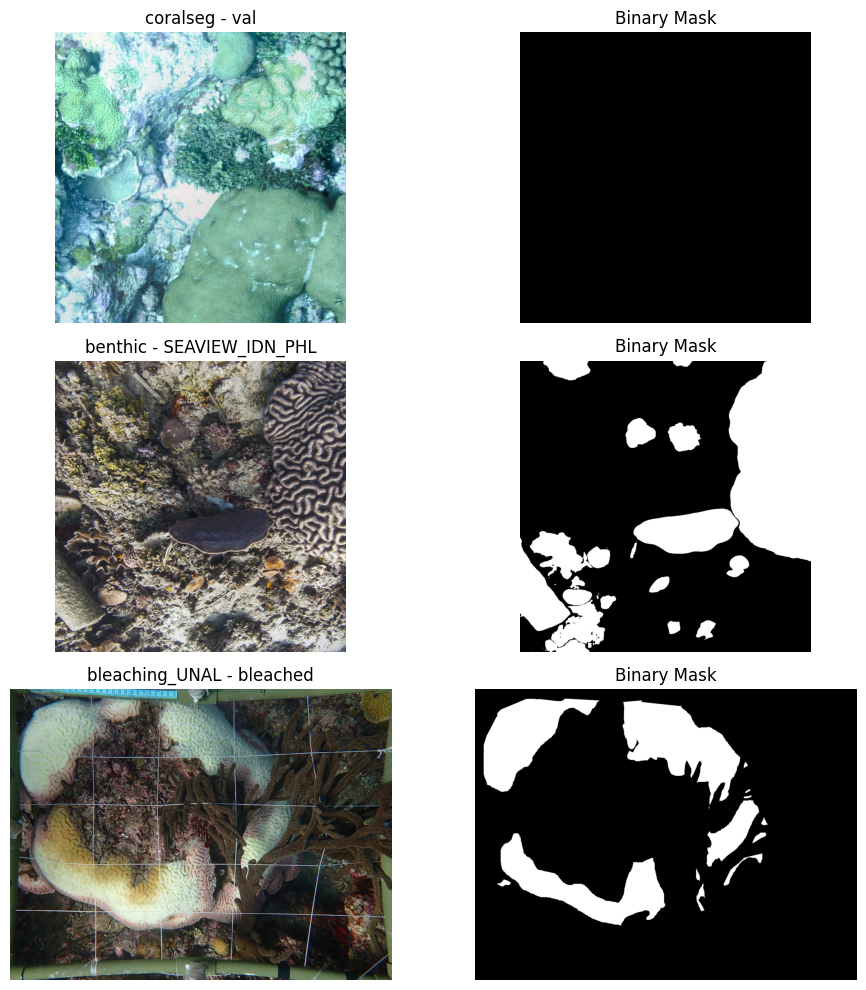

In [ ]:
import random
import matplotlib.pyplot as plt

samples = df_all.sample(3)
fig, axes = plt.subplots(3, 2, figsize=(10, 10))

for i, (_, row) in enumerate(samples.iterrows()):
    img = cv2.imread(row["image_path"])
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    mask = cv2.imread(row["mask_binary_path"], cv2.IMREAD_GRAYSCALE)

    axes[i, 0].imshow(img)
    axes[i, 0].set_title(f"{row['dataset']} - {row['site']}")
    axes[i, 0].axis("off")

    axes[i, 1].imshow(mask, cmap="gray")
    axes[i, 1].set_title("Binary Mask")
    axes[i, 1].axis("off")

plt.tight_layout()
plt.show()

# Section 3: Preprocessing

### 3.1 Load merged dataset

In [ ]:
# Section 3.1: Load Unified Dataset

import os, cv2, numpy as np, pandas as pd
from tqdm import tqdm

# Reload merged dataset
merged_csv = f"{OUTPUT_DIR}/merged_dataset_normalized.csv"
df = pd.read_csv(merged_csv)

print("Loaded merged dataset:", df.shape)
print(df.head(2))


Loaded merged dataset: (11624, 6)
   dataset               site  \
0  benthic  SEAFLOWER_BOLIVAR   
1  benthic  SEAFLOWER_BOLIVAR   

                                          image_path  \
0  /content/drive/MyDrive/01_data/benthic_dataset...   
1  /content/drive/MyDrive/01_data/benthic_dataset...   

                                           mask_path  \
0  /content/drive/MyDrive/01_data/benthic_dataset...   
1  /content/drive/MyDrive/01_data/benthic_dataset...   

                                    mask_binary_path mask_status_path  
0  /content/drive/MyDrive/coral_project_outputs/n...              NaN  
1  /content/drive/MyDrive/coral_project_outputs/n...              NaN  


### 3.2 Remove emtpy/invalid masks
Empty masks = no coral pixels (will confuse the model)

In [ ]:
# Section 3.2: Remove empty / invalid masks

valid_rows = []
coverage = []

print("...Checking for empty or invalid masks...")
for _, row in tqdm(df.iterrows(), total=len(df)):
    mask = cv2.imread(row["mask_binary_path"], cv2.IMREAD_GRAYSCALE)
    if mask is None:
        continue
    coral_pixels = np.count_nonzero(mask)
    coral_ratio = coral_pixels / (mask.shape[0]*mask.shape[1])
    if coral_pixels > 0:  # only non-empty
        valid_rows.append(row)
        coverage.append(coral_ratio)

df_clean = pd.DataFrame(valid_rows)
df_clean["coral_ratio"] = coverage

print(f"Remaining valid samples: {len(df_clean)} ({len(df_clean)/len(df)*100:.1f}% kept)")


...Checking for empty or invalid masks...


100%|██████████| 11624/11624 [04:00<00:00, 48.42it/s]

Remaining valid samples: 6501 (55.9% kept)


### 3.3 Remove very small regions
Extremely small/sparse masks can hurt model learning, and they are images that interpreting further along is hard as well, we assume this as a limitation.

In [ ]:
# Section 3.3: Filter small coral regions

threshold = 0.01  # coral covers at least 1% of image
df_clean = df_clean[df_clean["coral_ratio"] > threshold].reset_index(drop=True)

print(f"Samples after removing small coral areas: {len(df_clean)}")


Samples after removing small coral areas: 6222


### 3.4 Resize images+masks to (512 x 512)
This can be adjusted in order to optimize image quality or computaion speed, we found 512x512 was a good balance between not affecting model accuracy and maintaining an affordable computation effort.

In [ ]:
import os
import cv2
from tqdm import tqdm
import pandas as pd

# Directory to store resized data
RESIZED_DIR = os.path.join(OUTPUT_DIR, "resized_data")
os.makedirs(RESIZED_DIR, exist_ok=True)

new_records = []

for i, row in tqdm(df_clean.iterrows(), total=len(df_clean), desc="Resizing images and masks to 512x512"):
    try:
        img = cv2.imread(row["image_path"])
        mask = cv2.imread(row["mask_path"], cv2.IMREAD_GRAYSCALE)

        # Skip invalid pairs
        if img is None or mask is None:
            continue

        # Output paths
        base = os.path.splitext(os.path.basename(row["image_path"]))[0]
        img_out = os.path.join(RESIZED_DIR, f"{base}_img.png")
        mask_out = os.path.join(RESIZED_DIR, f"{base}_mask.png")

        # Skip if already resized
        if os.path.exists(img_out) and os.path.exists(mask_out):
            new_records.append({
                "dataset": row["dataset"],
                "site": row["site"],
                "image_resized": img_out,
                "mask_resized": mask_out
            })
            continue

        # Resize and save
        img_resized = cv2.resize(img, (512, 512))
        mask_resized = cv2.resize(mask, (512, 512))
        cv2.imwrite(img_out, img_resized)
        cv2.imwrite(mask_out, mask_resized)

        new_records.append({
            "dataset": row["dataset"],
            "site": row["site"],
            "image_resized": img_out,
            "mask_resized": mask_out
        })

    except Exception as e:
        print(f"Error resizing {row['image_path']}: {e}")
        continue

# Build new DataFrame from successful resizes
df_resized = pd.DataFrame(new_records)
print(f"Resized successfully: {len(df_resized)} / {len(df_clean)} samples")

# Save manifest
resized_csv = os.path.join(OUTPUT_DIR, "df_resized_manifest.csv")
df_resized.to_csv(resized_csv, index=False)
print(f"Manifest saved to: {resized_csv}")


Resizing images and masks to 512x512: 100%|██████████| 6222/6222 [33:33<00:00,  3.09it/s]  


Resized successfully: 4147 / 6222 samples
Manifest saved to: /content/drive/MyDrive/coral_project_outputs/df_resized_manifest.csv


### 3.5 Site-stratified Train/Val/Test split
Ensures domain robustness across reef locations.

In [ ]:
# Section 3.5: Site-Stratified Split

from sklearn.model_selection import train_test_split

train_list, val_list, test_list = [], [], []

for site, group in df_clean.groupby("site"):
    if len(group) < 10:  # skip tiny sites
        continue
    train, temp = train_test_split(group, test_size=0.3, random_state=42)
    val, test = train_test_split(temp, test_size=0.5, random_state=42)
    train_list.append(train)
    val_list.append(val)
    test_list.append(test)

df_train = pd.concat(train_list)
df_val   = pd.concat(val_list)
df_test  = pd.concat(test_list)

print(f"Train: {len(df_train)}, Val: {len(df_val)}, Test: {len(df_test)}")


### 3.6 Save Clean Dataset

In [ ]:
# Save Clean Dataset

split_dir = f"{OUTPUT_DIR}/dataset_splits"
os.makedirs(split_dir, exist_ok=True)

df_train.to_csv(f"{split_dir}/train_manifest.csv", index=False)
df_val.to_csv(f"{split_dir}/val_manifest.csv", index=False)
df_test.to_csv(f"{split_dir}/test_manifest.csv", index=False)

print("Succesfully saved manifests to:", split_dir)


### 3.7 Visual Sanity Check

In [ ]:
# Section 3.6: Visual Sanity Check

import random
import matplotlib.pyplot as plt

samples = df_clean.sample(3)
fig, axes = plt.subplots(3, 2, figsize=(10, 10))
for i, (_, row) in enumerate(samples.iterrows()):
    img = cv2.imread(row["image_resized"])
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    mask = cv2.imread(row["mask_resized"], cv2.IMREAD_GRAYSCALE)
    axes[i, 0].imshow(img)
    axes[i, 0].set_title(f"{row['dataset']} - {row['site']}")
    axes[i, 0].axis("off")
    axes[i, 1].imshow(mask, cmap="gray")
    axes[i, 1].set_title("Binary Mask (512x512)")
    axes[i, 1].axis("off")
plt.tight_layout()
plt.show()


# Section 4: Model Setup and Training

### 4.1 Imports and Environment Setup
Self-contained environment cell, for minimal code cells to run when rerunning model.

In [ ]:
# Section 4: Model Setup & Training

# Core imports
import os
import cv2
import time
import torch
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import tqdm

# ML / Vision imports
from torch.utils.data import Dataset, DataLoader
import albumentations as A
from albumentations.pytorch import ToTensorV2
import segmentation_models_pytorch as smp

# Paths
BASE_DIR = "/content/drive/MyDrive/01_data"
OUTPUT_DIR = "/content/drive/MyDrive/coral_project_outputs"
SPLIT_DIR = f"{OUTPUT_DIR}/dataset_splits"

# Dataset manifests
train_csv = os.path.join(SPLIT_DIR, "train_manifest.csv")
val_csv   = os.path.join(SPLIT_DIR, "val_manifest.csv")

df_train = pd.read_csv(train_csv)
df_val   = pd.read_csv(val_csv)

print(f"Loaded manifests | Train: {len(df_train)} | Val: {len(df_val)}")

# GPU Check
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)


### 4.2 Custom Dataset and Dataloader with Albumentations

We will use:
- Random flips: flips the images.
- Brightness/Contrast: alters image brightness and contrast of colors to simulate corals in different colors and water clarities.
- Hue and Saturation: changing how dark/light colors look and how strong/vibrant the color is, which correlates to water turbidity and underwater imagery variations.
- Gaussian Blur: smooths and softens an image to blur details, it reduces sharp details, noise, artifacts, which gives smoother more natural look.
- Coarse dropout: to prevent overfitting
- CLAHE: helps reduce noise in uniform regions. Contrary to traditional histogram equalization which tends to amplify noise in areas with little intensity variation, CLAHE mitigates it by clipping the histogram and redistributing values more evenly (https://medium.com/imagecraft/histogram-equalization-clahe-algorithm-8841d402fc76)

In [ ]:
# Section 4.2: Dataset & DataLoader

class CoralSegDataset(Dataset):
    def __init__(self, df, augment=False):
        self.df = df
        self.augment = augment
        self.transform = self.get_transform(augment)

    def __len__(self):
        return len(self.df)

    def get_transform(self, augment):
        if augment:
            return A.Compose([
                A.HorizontalFlip(p=0.5),
                A.VerticalFlip(p=0.5),
                A.RandomRotate90(p=0.5),
                A.RandomBrightnessContrast(p=0.5),
                A.CLAHE(clip_limit=2.0, tile_grid_size=(8,8), p=0.3),
                A.HueSaturationValue(hue_shift_limit=10, sat_shift_limit=15, val_shift_limit=10, p=0.5),
                A.GaussianBlur(blur_limit=3, p=0.3),
                A.CoarseDropout(max_holes=8, max_height=32, max_width=32, fill_value=0, p=0.3),
                A.Normalize(),
                ToTensorV2()
            ])
        else:
            return A.Compose([
                A.Normalize(),
                ToTensorV2()
            ])

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        image = cv2.imread(row["image_resized"])
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        mask  = cv2.imread(row["mask_resized"], cv2.IMREAD_GRAYSCALE)
        mask  = (mask > 127).astype("float32")

        transformed = self.transform(image=image, mask=mask)
        return transformed["image"], transformed["mask"].unsqueeze(0)

# Create loaders
train_ds = CoralSegDataset(df_train, augment=True)
val_ds   = CoralSegDataset(df_val, augment=False)

train_loader = DataLoader(train_ds, batch_size=8, shuffle=True, num_workers=2)
val_loader   = DataLoader(val_ds, batch_size=8, shuffle=False, num_workers=2)

batch = next(iter(train_loader))
print("Dataloader OK — imgs:", batch[0].shape, "| masks:", batch[1].shape)


### 4.3 Model Definition
Defining U-Net with EfficientNet-B0 encoder, combining BCE and Dice loss for stability, decided based on best model results after testing. Everything in the model process in already based on testing for several variations in model characteristics as well as already having the optuna hyperparameter optimization results as the set parameters.

In [ ]:
# Section 4.3: Model, Loss & Optimizer

ENCODER = "efficientnet-b0"
ENCODER_WEIGHTS = "imagenet"

model = smp.Unet(
    encoder_name=ENCODER,
    encoder_weights=ENCODER_WEIGHTS,
    in_channels=3,
    classes=1,
    activation=None
).to(device)

# Loss: BCE + Dice
bce = torch.nn.BCEWithLogitsLoss()
dice = smp.losses.DiceLoss(mode="binary")

def combined_loss(pred, target):
    return 0.7 * bce(pred, target) + 0.3 * dice(pred, target)

optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=1e-5)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', factor=0.5, patience=3, verbose=True)



### 4.4 Training Loop with IoU and Dice Evaluation

In [ ]:
# 4.4: Training Loop (with fixed combined loss)

def compute_iou(preds, masks, threshold=0.5):
    preds = (preds > threshold).float()
    intersection = (preds * masks).sum(dim=(1,2,3))
    union = preds.sum(dim=(1,2,3)) + masks.sum(dim=(1,2,3)) - intersection
    return (intersection / (union + 1e-7)).mean().item()

EPOCHS = 30
best_iou = 0
train_history, val_history = [], []

for epoch in range(EPOCHS):
    model.train()
    train_loss = []
    for imgs, masks in tqdm(train_loader, desc=f"Epoch {epoch+1}/{EPOCHS} [Train]"):
        imgs, masks = imgs.to(device), masks.to(device)
        preds = model(imgs)
        loss = combined_loss(preds, masks)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        train_loss.append(loss.item())

    # Validation
    model.eval()
    val_loss, val_iou = [], []
    with torch.no_grad():
        for imgs, masks in tqdm(val_loader, desc=f"Epoch {epoch+1}/{EPOCHS} [Val]"):
            imgs, masks = imgs.to(device), masks.to(device)
            preds = model(imgs)
            loss = combined_loss(preds, masks)
            val_loss.append(loss.item())
            val_iou.append(compute_iou(torch.sigmoid(preds), masks))

    mean_train, mean_val, mean_iou = np.mean(train_loss), np.mean(val_loss), np.mean(val_iou)
    train_history.append(mean_train)
    val_history.append(mean_val)

    print(f"Epoch {epoch+1}/{EPOCHS} | Train: {mean_train:.4f} | Val: {mean_val:.4f} | IoU: {mean_iou:.4f}")

    # LR scheduler reacts to validation IoU
    scheduler.step(mean_iou)

    # Save best model
    if mean_iou > best_iou:
        best_iou = mean_iou
        torch.save(model.state_dict(), f"{OUTPUT_DIR}/best_model.pth")
        print("💾 Saved new best model.")

print("Training complete! Best IoU:", best_iou)


### 4.5 Visualize Predictions vs Ground Truth

In [ ]:
# Section 4.5: Visualization of Predictions

model.eval()
samples = random.sample(range(len(val_ds)), 3)
fig, axes = plt.subplots(len(samples), 3, figsize=(12, 10))

for i, idx in enumerate(samples):
    img, mask = val_ds[idx]
    img_np = img.permute(1,2,0).cpu().numpy()
    pred = torch.sigmoid(model(img.unsqueeze(0).to(device))).cpu().detach().squeeze().numpy()

    axes[i,0].imshow(img_np)
    axes[i,0].set_title("Original Image"); axes[i,0].axis("off")

    axes[i,1].imshow(mask.squeeze(), cmap="gray")
    axes[i,1].set_title("Ground Truth Mask"); axes[i,1].axis("off")

    axes[i,2].imshow(pred > 0.5, cmap="gray")
    axes[i,2].set_title("Predicted Mask"); axes[i,2].axis("off")

plt.tight_layout()
plt.show()
